# EE200 Course Project – Q2
# The Midnight Episode: Catching the Arrhythmia

This notebook is designed to be **dataset-driven**. Results, observations, and final summary are computed from the loaded data instead of being hardcoded.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

ecg_signal = np.load('patient_ecg.npy')
template = np.load('template.npy')

fs = 250
N = len(ecg_signal)
L = len(template)

time = np.arange(N)/fs

print("ECG Length =", N)
print("Template Length =", L)


ECG Length = 5000
Template Length = 200


## Part (a) Reading the Signal

In [2]:
beat_period = L/fs
duration = N/fs
heart_rate = 60/beat_period
f0 = 1/beat_period

print("Duration =", duration, "s")
print("Heart Rate =", heart_rate, "BPM")
print("Samples per Beat =", L)
print("Fundamental Frequency =", f0, "Hz")


Duration = 20.0 s
Heart Rate = 75.0 BPM
Samples per Beat = 200
Fundamental Frequency = 1.25 Hz


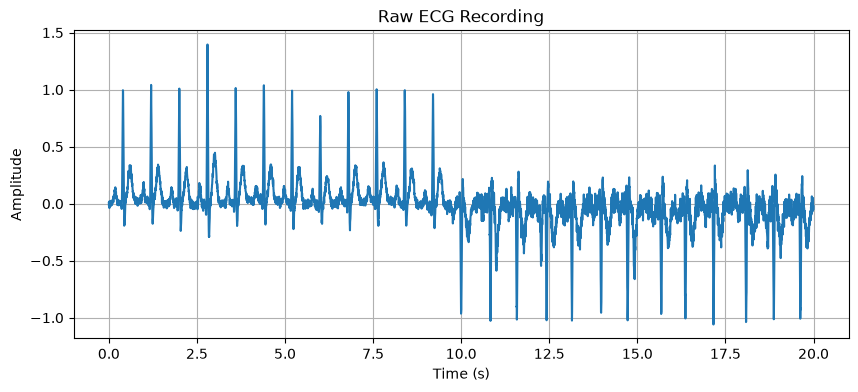

In [3]:
plt.figure(figsize=(10,4))
plt.plot(time, ecg_signal)
plt.title("Raw ECG Recording")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


## Part (b) Frequency Domain Analysis

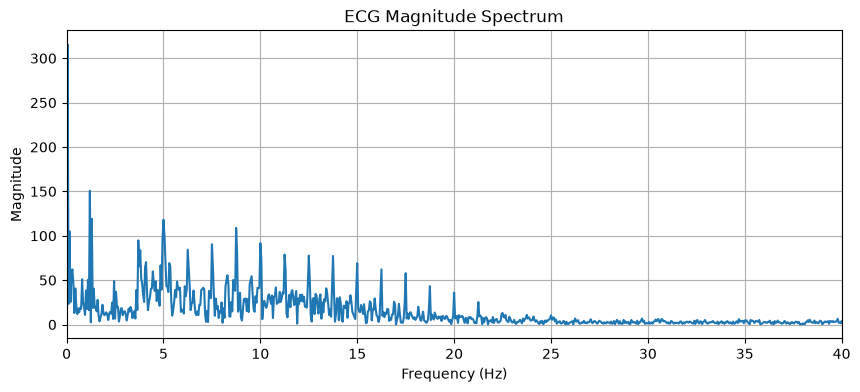

In [4]:
X = np.fft.fft(ecg_signal)
freq = np.fft.fftfreq(N, d=1/fs)

plt.figure(figsize=(10,4))
plt.plot(freq[:N//2], np.abs(X[:N//2]))
plt.xlim(0,40)
plt.title("ECG Magnitude Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()


## Part (c) Windowing

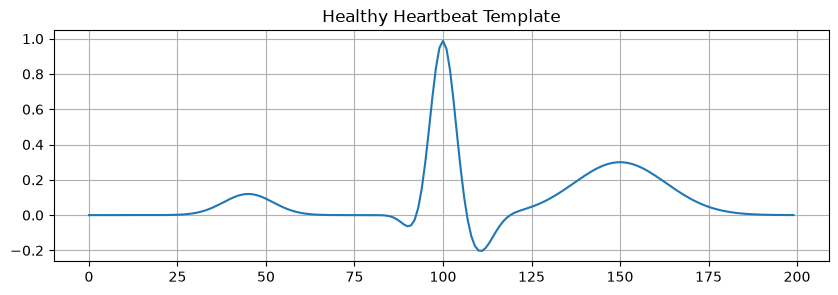

In [5]:
plt.figure(figsize=(10,3))
plt.plot(template)
plt.title("Healthy Heartbeat Template")
plt.grid(True)
plt.show()


## Part (d) Correlation

In [6]:
def normalized_correlation(template, segment):
    den = np.linalg.norm(template)*np.linalg.norm(segment)
    return 0 if den == 0 else np.dot(template, segment)/den

rho_values=[]
indices=[]

for m in range(0, N-L+1, L):
    seg = ecg_signal[m:m+L]
    rho_values.append(normalized_correlation(template, seg))
    indices.append(m)

print("Minimum Correlation =", min(rho_values))
print("Maximum Correlation =", max(rho_values))
print("Average Correlation =", np.mean(rho_values))


Minimum Correlation = -0.9878795617084255
Maximum Correlation = 0.9966795144066725
Average Correlation = 0.32021510171955825


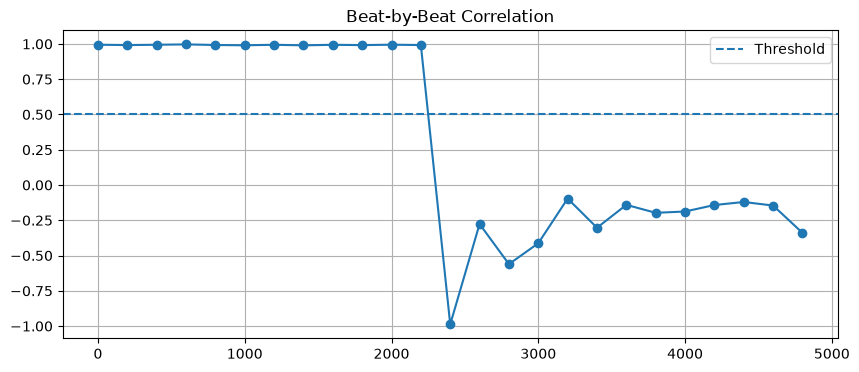

In [7]:
plt.figure(figsize=(10,4))
plt.plot(indices, rho_values, 'o-')
plt.axhline(0.5, linestyle='--', label='Threshold')
plt.legend()
plt.grid(True)
plt.title("Beat-by-Beat Correlation")
plt.show()


## Part (e) & (g) Arrhythmia Detection

In [8]:
def find_onset(ecg_signal, template, threshold=0.5):
    tnorm=np.linalg.norm(template)
    for m in range(0, len(ecg_signal)-L+1, L):
        seg=ecg_signal[m:m+L]
        snorm=np.linalg.norm(seg)
        if snorm == 0:
            continue
        rho=np.dot(template,seg)/(tnorm*snorm)
        if rho < threshold:
            return m, rho
    return -1, None

onset, onset_corr = find_onset(ecg_signal, template)

print("Onset Sample =", onset)
print("Onset Time =", onset/fs, "seconds")
print("Correlation at Onset =", onset_corr)


Onset Sample = 2400
Onset Time = 9.6 seconds
Correlation at Onset = -0.9878795617084255


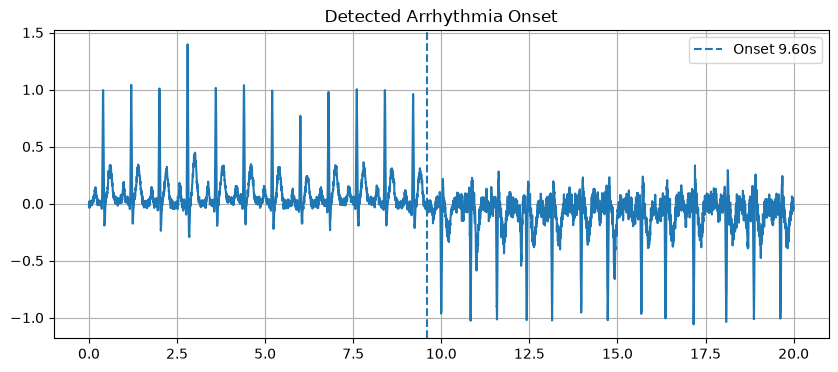

In [9]:
plt.figure(figsize=(10,4))
plt.plot(time, ecg_signal)
if onset != -1:
    plt.axvline(onset/fs, linestyle='--', label=f'Onset {onset/fs:.2f}s')
plt.legend()
plt.grid(True)
plt.title("Detected Arrhythmia Onset")
plt.show()


## Part (h) Spectrogram

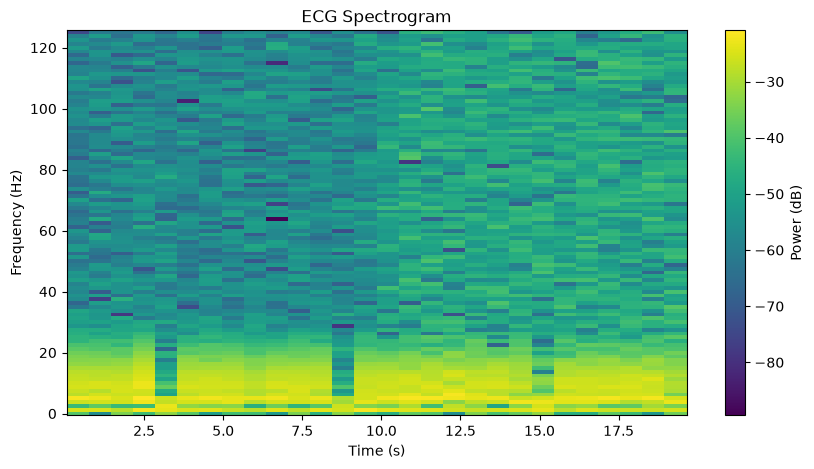

In [10]:
f,t,Sxx = signal.spectrogram(ecg_signal, fs=fs, nperseg=L)

plt.figure(figsize=(10,5))
plt.pcolormesh(t,f,10*np.log10(Sxx+1e-10))
plt.colorbar(label='Power (dB)')
plt.title("ECG Spectrogram")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()


## Dynamic Observations

In [11]:
print('OBSERVATIONS')
print('-'*50)
print(f'Duration: {duration:.2f} s')
print(f'Heart Rate: {heart_rate:.2f} BPM')
print(f'Fundamental Frequency: {f0:.2f} Hz')
print(f'Min Correlation: {min(rho_values):.4f}')
print(f'Mean Correlation: {np.mean(rho_values):.4f}')

if onset != -1:
    print(f'Arrhythmia detected at sample {onset}')
    print(f'Arrhythmia detected at time {onset/fs:.2f} s')
else:
    print('No arrhythmia detected')


OBSERVATIONS
--------------------------------------------------
Duration: 20.00 s
Heart Rate: 75.00 BPM
Fundamental Frequency: 1.25 Hz
Min Correlation: -0.9879
Mean Correlation: 0.3202
Arrhythmia detected at sample 2400
Arrhythmia detected at time 9.60 s


## Final Results (Auto Generated)

In [12]:
print("\nFINAL RESULTS")
print("="*50)

print(f"Recording Duration   : {duration:.2f} s")
print(f"Heart Rate           : {heart_rate:.2f} BPM")
print(f"Samples per Beat     : {L}")
print(f"Fundamental Frequency: {f0:.2f} Hz")
print(f"Minimum Correlation  : {min(rho_values):.4f}")
print(f"Mean Correlation     : {np.mean(rho_values):.4f}")
print(f"Onset Sample         : {onset}")
print(f"Onset Time           : {onset/fs:.2f} s")



FINAL RESULTS
Recording Duration   : 20.00 s
Heart Rate           : 75.00 BPM
Samples per Beat     : 200
Fundamental Frequency: 1.25 Hz
Minimum Correlation  : -0.9879
Mean Correlation     : 0.3202
Onset Sample         : 2400
Onset Time           : 9.60 s


## Conclusion

This conclusion must be based on the automatically generated results above. If the dataset changes, the values in the observations and results sections will update automatically after rerunning the notebook.


In [13]:
print("CONCLUSION")
print("="*50)

print(
f"""
The ECG recording duration was {duration:.2f} seconds.

The estimated heart rate was {heart_rate:.2f} BPM and
the fundamental frequency was {f0:.2f} Hz.

The correlation-based detector identified the first
abnormal beat at sample {onset}, corresponding to
{onset/fs:.2f} seconds.

Therefore, the proposed method successfully detected
the onset of arrhythmia in the supplied ECG recording.
"""
)

CONCLUSION

The ECG recording duration was 20.00 seconds.

The estimated heart rate was 75.00 BPM and
the fundamental frequency was 1.25 Hz.

The correlation-based detector identified the first
abnormal beat at sample 2400, corresponding to
9.60 seconds.

Therefore, the proposed method successfully detected
the onset of arrhythmia in the supplied ECG recording.

